<a href="https://colab.research.google.com/github/ayuannisa17/PCdVK_ganjil_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week10 – Dasar-Dasar Deteksi Objek


## 1. Import library dan Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, cv2, random, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = '/content/drive/MyDrive/PCdVK'

def cari_file(nama):
    hasil = glob.glob(os.path.join(BASE_DIR, '**', nama), recursive=True)
    if not hasil:
        raise FileNotFoundError(f'{nama} tidak ditemukan di {BASE_DIR}. Periksa nama/lokasi file.')
    return hasil[0]

def tampil(gambar, judul='', cmap=None, figsize=(8,5)):
    plt.figure(figsize=figsize)
    plt.imshow(gambar, cmap=cmap)
    plt.title(judul); plt.axis('off'); plt.show()

print('Folder dataset:', BASE_DIR, os.path.isdir(BASE_DIR))

Mounted at /content/drive
Folder dataset: /content/drive/MyDrive/PCdVK True


## D1 – Praktikum Deteksi Obyek Dasar
### 2. Enam metode Template Matching

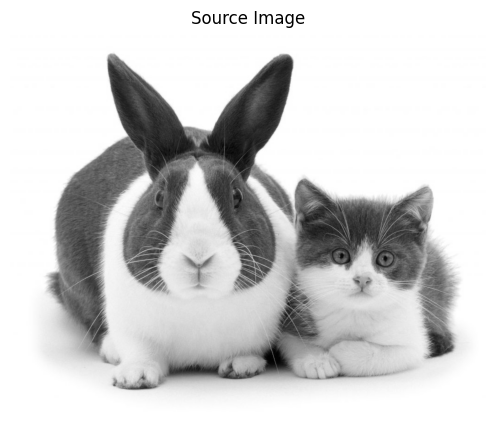

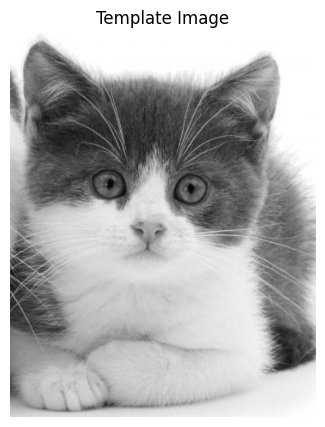

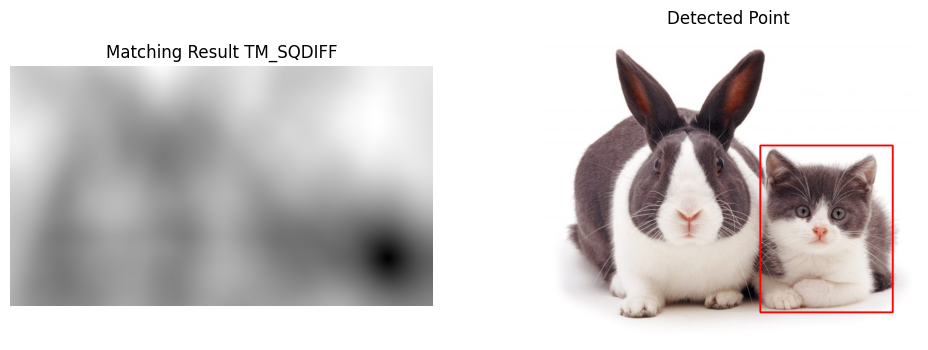

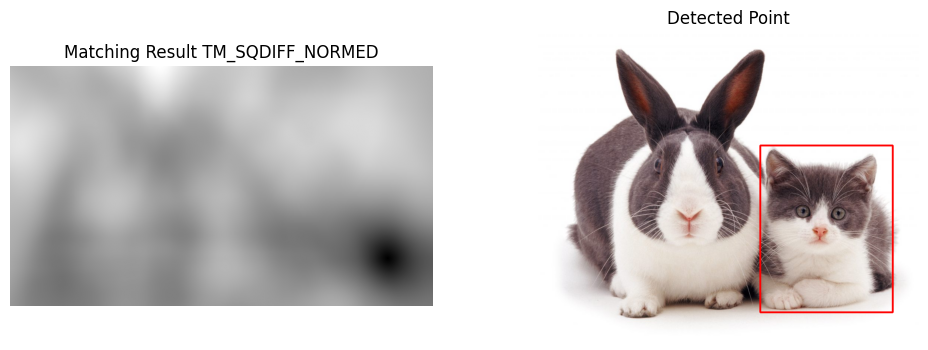

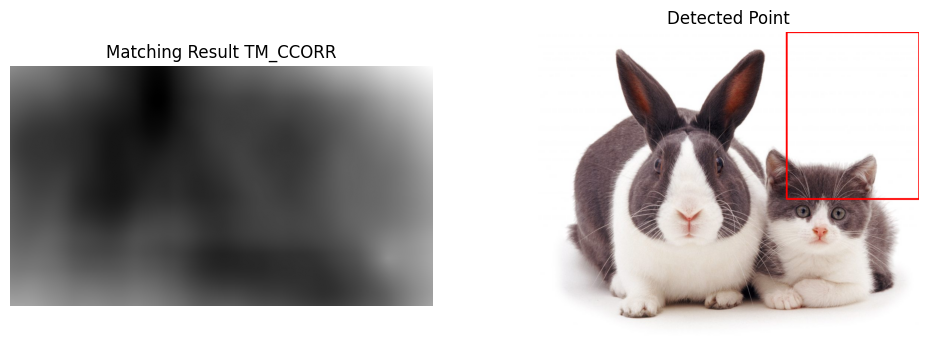

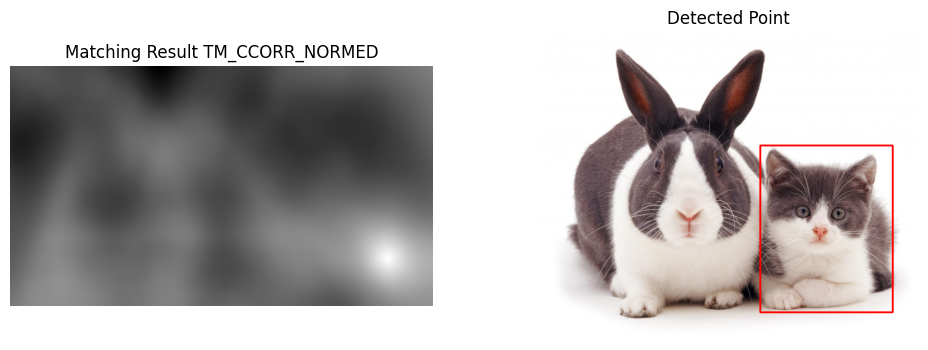

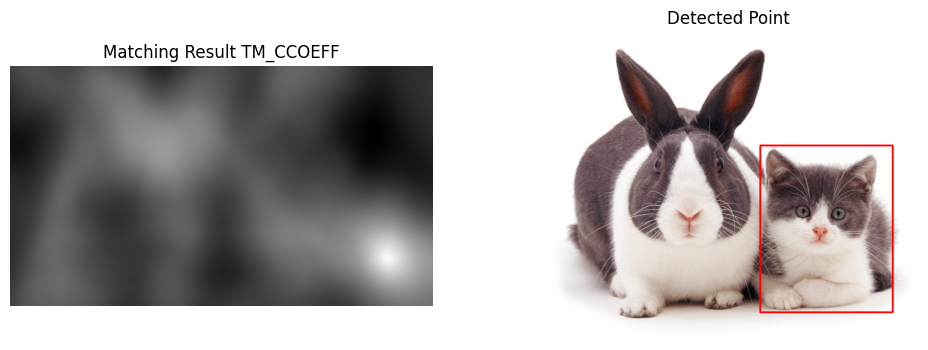

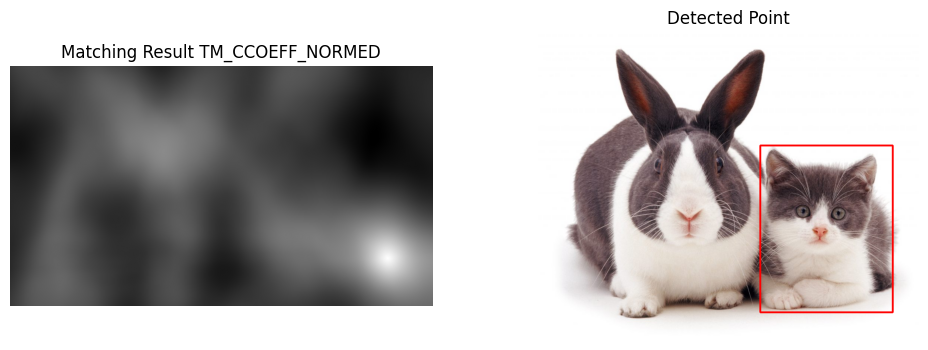

In [2]:
source_color = cv2.imread(cari_file('cats_and_bunnies.jpg'))
template_color = cv2.imread(cari_file('cat2_templatejpg.jpg'))
source = cv2.cvtColor(source_color, cv2.COLOR_BGR2GRAY)
template = cv2.cvtColor(template_color, cv2.COLOR_BGR2GRAY)
h, w = template.shape
tampil(cv2.cvtColor(source, cv2.COLOR_GRAY2RGB), 'Source Image')
tampil(cv2.cvtColor(template, cv2.COLOR_GRAY2RGB), 'Template Image')

methods = [
 ('TM_SQDIFF', cv2.TM_SQDIFF), ('TM_SQDIFF_NORMED', cv2.TM_SQDIFF_NORMED),
 ('TM_CCORR', cv2.TM_CCORR), ('TM_CCORR_NORMED', cv2.TM_CCORR_NORMED),
 ('TM_CCOEFF', cv2.TM_CCOEFF), ('TM_CCOEFF_NORMED', cv2.TM_CCOEFF_NORMED)
]
for name, method in methods:
    result = cv2.matchTemplate(source, template, method)
    min_v, max_v, min_p, max_p = cv2.minMaxLoc(result)
    p = min_p if method in (cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED) else max_p
    out = source_color.copy()
    cv2.rectangle(out, p, (p[0]+w, p[1]+h), (0,0,255), 3)
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    ax[0].imshow(result, cmap='gray'); ax[0].set_title('Matching Result '+name); ax[0].axis('off')
    ax[1].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); ax[1].set_title('Detected Point'); ax[1].axis('off')
    plt.show()

### 3. Template Matching manual tanpa OpenCV untuk multiple object (Bahrain)


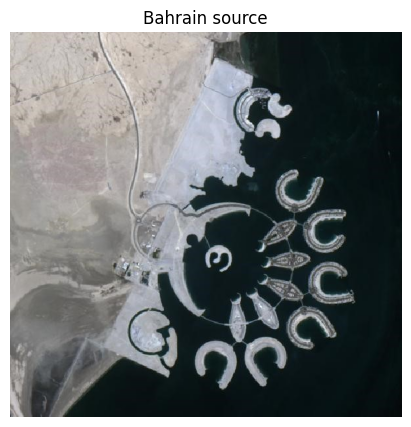

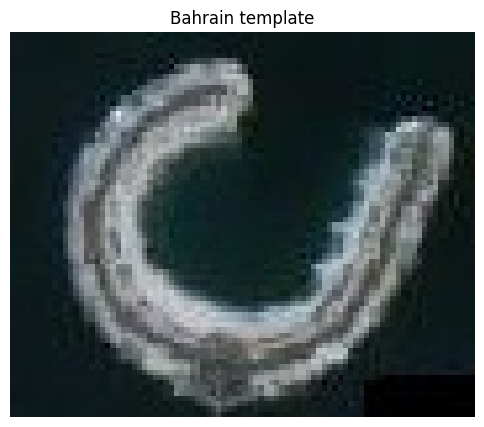

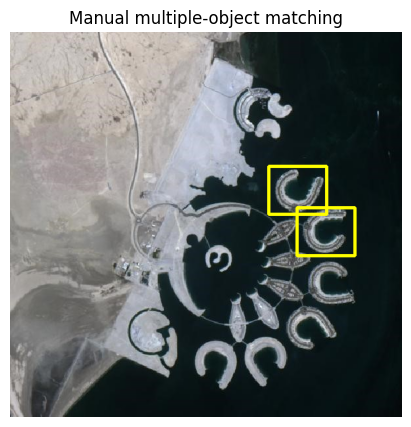

In [3]:
source_color = cv2.imread(cari_file('bahrain.jpg'))
template_color = cv2.imread(cari_file('bahrain-template.jpg'))
src = cv2.cvtColor(source_color, cv2.COLOR_BGR2GRAY).astype(np.float32)
tmp = cv2.cvtColor(template_color, cv2.COLOR_BGR2GRAY).astype(np.float32)
th, tw = tmp.shape
tc = tmp - tmp.mean()
tn = np.sqrt((tc**2).sum()) + 1e-8
scores = np.full((src.shape[0]-th+1, src.shape[1]-tw+1), -1.0)
for y in range(scores.shape[0]):
    for x in range(scores.shape[1]):
        patch = src[y:y+th, x:x+tw]
        pc = patch - patch.mean()
        scores[y,x] = (pc*tc).sum() / (np.sqrt((pc**2).sum())*tn + 1e-8)

out = source_color.copy()
for _ in range(6):
    y,x = np.unravel_index(np.argmax(scores), scores.shape)
    if scores[y,x] < 0.55: break
    cv2.rectangle(out, (x,y), (x+tw,y+th), (0,255,255), 3)
    scores[max(0,y-th//2):min(scores.shape[0],y+th//2+1),
           max(0,x-tw//2):min(scores.shape[1],x+tw//2+1)] = -1
tampil(cv2.cvtColor(source_color, cv2.COLOR_BGR2RGB), 'Bahrain source')
tampil(cv2.cvtColor(template_color, cv2.COLOR_BGR2RGB), 'Bahrain template')
tampil(cv2.cvtColor(out, cv2.COLOR_BGR2RGB), 'Manual multiple-object matching')

### 4. Sobel, Canny, dan Laplacian Edge Detection

In [ ]:
img = cv2.imread(cari_file('car-park.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sx, sy))
canny = cv2.Canny(gray, 100, 200)
lap = cv2.convertScaleAbs(cv2.Laplacian(gray, cv2.CV_64F))
fig, ax = plt.subplots(2,2, figsize=(13,9))
ax[0,0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0,0].set_title('Original')
ax[0,1].imshow(sobel,cmap='gray'); ax[0,1].set_title('Sobel')
ax[1,0].imshow(canny,cmap='gray'); ax[1,0].set_title('Canny')
ax[1,1].imshow(lap,cmap='gray'); ax[1,1].set_title('Laplacian')
for a in ax.ravel(): a.axis('off')
plt.show()

### 5. Harris Corner dan Shi-Tomasi

In [ ]:
img = cv2.imread(cari_file('chess-board.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
harris = cv2.cornerHarris(np.float32(gray), 2, 3, 0.04)
harris = cv2.dilate(harris, None)
out_h = img.copy()
out_h[harris > 0.01*harris.max()] = [0,0,255]
corners = cv2.goodFeaturesToTrack(gray, 100, 0.01, 10)
out_s = img.copy()
if corners is not None:
    for p in np.intp(corners):
        x,y = p.ravel()
        cv2.circle(out_s, (x,y), 5, (255,0,0), -1)
fig, ax = plt.subplots(1,2, figsize=(13,6))
ax[0].imshow(cv2.cvtColor(out_h,cv2.COLOR_BGR2RGB)); ax[0].set_title('Harris')
ax[1].imshow(cv2.cvtColor(out_s,cv2.COLOR_BGR2RGB)); ax[1].set_title('Shi-Tomasi')
for a in ax: a.axis('off')
plt.show()

### 6. Hough Transform untuk Grid Detection

In [ ]:
img = cv2.imread(cari_file('sudoku.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)
dilated = cv2.dilate(edges, np.ones((3,3),np.uint8), iterations=1)
processed = cv2.erode(dilated, np.ones((3,3),np.uint8), iterations=1)
lines = cv2.HoughLinesP(processed, 1, np.pi/180, 100, minLineLength=80, maxLineGap=15)
out = img.copy()
if lines is not None:
    for line in lines:
        x1,y1,x2,y2 = line[0]
        cv2.line(out, (x1,y1), (x2,y2), (0,0,255), 2)
fig, ax = plt.subplots(1,2, figsize=(13,6))
ax[0].imshow(edges,cmap='gray'); ax[0].set_title('Canny edges')
ax[1].imshow(cv2.cvtColor(out,cv2.COLOR_BGR2RGB)); ax[1].set_title('Hough grid')
for a in ax: a.axis('off')
plt.show()

### 7. Contour Detection

In [ ]:
img = cv2.imread(cari_file('laptop.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5,5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
contours, hierarchy = cv2.findContours(binary, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
out = img.copy()
cv2.drawContours(out, contours, -1, (0,0,255), 2)
print('Jumlah kontur:', len(contours))
tampil(cv2.cvtColor(out,cv2.COLOR_BGR2RGB), 'Contour Detection')

## D2 – Feature Matching dan Face Detection
### Persiapan Haar Cascade

In [ ]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades+'haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades+'haarcascade_eye.xml')
smile_cascade = cv2.CascadeClassifier(cv2.data.haarcascades+'haarcascade_smile.xml')

### 8. Face Detection untuk gambar pada folder facedet

In [ ]:
folders = glob.glob(os.path.join(BASE_DIR, '**', 'facedet'), recursive=True)
if not folders:
    print('Folder facedet tidak ditemukan. Periksa struktur dataset.')
else:
    files = []
    for ext in ('*.jpg','*.jpeg','*.png','*.bmp'):
        files += glob.glob(os.path.join(folders[0], ext))
    print('Jumlah gambar:', len(files))
    for path in files:
        img = cv2.imread(path)
        if img is None: continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, 1.1, 5)
        out = img.copy()
        for (x,y,w,h) in faces: cv2.rectangle(out,(x,y),(x+w,y+h),(0,255,0),2)
        tampil(cv2.cvtColor(out,cv2.COLOR_BGR2RGB), os.path.basename(path))

### 9. Deteksi wajah kucing


In [ ]:
xml_cat = glob.glob(os.path.join(BASE_DIR, '**', '*cat*.xml'), recursive=True)
if xml_cat:
    cat_cascade = cv2.CascadeClassifier(xml_cat[0])
    # Ganti nama gambar jika file kucing pada dataset berbeda.
    cat_path = cari_file('kitten1.png')
    img = cv2.imread(cat_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    boxes = cat_cascade.detectMultiScale(gray, 1.05, 3, minSize=(30,30))
    out = img.copy()
    for (x,y,w,h) in boxes: cv2.rectangle(out,(x,y),(x+w,y+h),(255,255,255),2)
    print('Jumlah deteksi:', len(boxes))
    tampil(cv2.cvtColor(out,cv2.COLOR_BGR2RGB), 'Cat face detection')
else:
    print('XML khusus kucing tidak ditemukan. Tambahkan XML cat-face detector untuk menyelesaikan nomor ini.')

### 10. Eyes Detection pada wajah Pak Prabowo

In [ ]:
img = cv2.imread(cari_file('prabowo.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.1, 5)
out = img.copy()
for (x,y,w,h) in faces:
    roi_g = gray[y:y+h, x:x+w]
    roi_c = out[y:y+h, x:x+w]
    eyes = eye_cascade.detectMultiScale(roi_g, 1.1, 5)
    for (ex,ey,ew,eh) in eyes: cv2.rectangle(roi_c,(ex,ey),(ex+ew,ey+eh),(255,255,255),2)
tampil(cv2.cvtColor(out,cv2.COLOR_BGR2RGB), 'Eyes Detection')

### 11. Smile Detection pada gambar people

In [ ]:
img = cv2.imread(cari_file('people.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.1, 5)
out = img.copy()
for (x,y,w,h) in faces:
    roi_g = gray[y:y+h, x:x+w]
    roi_c = out[y:y+h, x:x+w]
    smiles = smile_cascade.detectMultiScale(roi_g, 1.7, 20, minSize=(20,20))
    for (sx,sy,sw,sh) in smiles: cv2.rectangle(roi_c,(sx,sy),(sx+sw,sy+sh),(0,255,0),2)
tampil(cv2.cvtColor(out,cv2.COLOR_BGR2RGB), 'Smile Detection')

### 12. Face Tracking menggunakan Google Colab


In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io

def ambil_frame():
    display(Javascript('''
    async function ambilFrame() {
      const div=document.createElement('div');
      const btn=document.createElement('button'); btn.textContent='Ambil frame';
      const video=document.createElement('video'); video.style.display='block';
      div.appendChild(btn); div.appendChild(video); document.body.appendChild(div);
      const stream=await navigator.mediaDevices.getUserMedia({video:true});
      video.srcObject=stream; await video.play();
      await new Promise(resolve=>btn.onclick=resolve);
      const canvas=document.createElement('canvas');
      canvas.width=video.videoWidth; canvas.height=video.videoHeight;
      canvas.getContext('2d').drawImage(video,0,0);
      stream.getTracks().forEach(t=>t.stop()); div.remove();
      return canvas.toDataURL('image/jpeg');
    }
    '''))
    data = eval_js('ambilFrame()')
    return np.array(Image.open(io.BytesIO(b64decode(data.split(',')[1]))))

frame = ambil_frame()
bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.1, 5)
for (x,y,w,h) in faces: cv2.rectangle(bgr,(x,y),(x+w,y+h),(0,255,0),2)
tampil(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB), 'Face detection webcam')

### 13. Blurring bagian wajah yang terdeteksi

In [ ]:
img = cv2.imread(cari_file('prabowo.jpg'))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.1, 5)
out = img.copy()
for (x,y,w,h) in faces:
    out[y:y+h, x:x+w] = cv2.medianBlur(out[y:y+h, x:x+w], 31)
tampil(cv2.cvtColor(out,cv2.COLOR_BGR2RGB), 'Face Blurring')

### 14. Mengolah gambar KTM

In [ ]:
# Ubah nama file jika foto KTM milikmu tidak bernama KTM.jpg.
ktm = cv2.imread(cari_file('KTM.jpg'))
tampil(cv2.cvtColor(ktm,cv2.COLOR_BGR2RGB), 'Foto KTM', figsize=(10,6))

#### 14c. Deteksi objek KTM dengan Feature Matching (ORB)


In [ ]:
template = cv2.imread(cari_file('KTM.jpg'), cv2.IMREAD_GRAYSCALE)
source = cv2.imread(cari_file('KTM_bersama_barang.jpg'))
source_gray = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
orb = cv2.ORB_create(nfeatures=1500)
kp1, des1 = orb.detectAndCompute(template, None)
kp2, des2 = orb.detectAndCompute(source_gray, None)
if des1 is None or des2 is None:
    print('Fitur tidak cukup ditemukan; gunakan foto yang lebih jelas.')
else:
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
    matches = sorted(matcher.match(des1,des2), key=lambda m:m.distance)
    result = cv2.drawMatches(template,kp1,source_gray,kp2,matches[:50],None,
                             flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    tampil(result, 'ORB Feature Matching KTM', figsize=(14,7))

## D3 – Pengayaan: Pengenalan Karakter KTM dengan CNN


### D3.1 Persiapan dataset training

In [ ]:
DATADIR = os.path.join(BASE_DIR, 'dataset', 'training')
width, height = 100, 100
if not os.path.isdir(DATADIR):
    print('Buat folder dataset/training dan subfolder karakter terlebih dahulu.')
else:
    dirs = sorted([d for d in os.listdir(DATADIR) if os.path.isdir(os.path.join(DATADIR,d))])
    training_data = []
    for label, char_name in enumerate(dirs):
        folder = os.path.join(DATADIR,char_name)
        for filename in os.listdir(folder):
            arr = cv2.imread(os.path.join(folder,filename), cv2.IMREAD_GRAYSCALE)
            if arr is not None:
                training_data.append([cv2.resize(arr,(width,height)),label])
    random.shuffle(training_data)
    X = np.array([item[0] for item in training_data]).reshape(-1,width,height,1)
    Y = np.array([item[1] for item in training_data])
    with open(os.path.join(BASE_DIR,'X.pickle'),'wb') as f: pickle.dump(X,f)
    with open(os.path.join(BASE_DIR,'Y.pickle'),'wb') as f: pickle.dump(Y,f)
    with open(os.path.join(BASE_DIR,'kelas.pickle'),'wb') as f: pickle.dump(dirs,f)
    print('Jumlah data:',len(training_data),'Jumlah kelas:',len(dirs),dirs)

### D3.2 Training CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

xf, yf = os.path.join(BASE_DIR,'X.pickle'), os.path.join(BASE_DIR,'Y.pickle')
if not (os.path.exists(xf) and os.path.exists(yf)):
    print('Jalankan persiapan dataset terlebih dahulu.')
else:
    with open(xf,'rb') as f: X = pickle.load(f)
    with open(yf,'rb') as f: Y = pickle.load(f)
    Y = to_categorical(Y)
    X = X.astype('float32')/255.0
    jumlah_kelas = Y.shape[1]
    inputs = Input(shape=(100,100,1))
    z = ZeroPadding2D(padding=(2,2))(inputs)
    z = Conv2D(16,(5,5),activation='relu')(z)
    z = MaxPooling2D((2,2))(z)
    z = Conv2D(32,(3,3),activation='relu')(z)
    z = Conv2D(32,(3,3),activation='relu')(z)
    z = MaxPooling2D((2,2))(z)
    z = Conv2D(64,(3,3),activation='relu')(z)
    z = Flatten()(z)
    z = Dense(256,activation='relu')(z)
    z = Dense(64,activation='relu')(z)
    outputs = Dense(jumlah_kelas,activation='softmax')(z)
    model = Model(inputs,outputs)
    model.compile(optimizer=Adam(learning_rate=0.0001),
                  loss='categorical_crossentropy',metrics=['accuracy'])
    history = model.fit(X,Y,epochs=20,verbose=1,validation_split=0.2)
    model.save(os.path.join(BASE_DIR,'anpr.keras'))
    print('Akurasi training:',history.history['accuracy'][-1])
    print('Akurasi validasi:',history.history['val_accuracy'][-1])

### D3.3 Testing karakter

In [ ]:
testing_dir = os.path.join(BASE_DIR,'dataset','testing')
model_path = os.path.join(BASE_DIR,'anpr.keras')
kelas_path = os.path.join(BASE_DIR,'kelas.pickle')
if not (os.path.isdir(testing_dir) and os.path.exists(model_path) and os.path.exists(kelas_path)):
    print('Folder testing/model/kelas belum tersedia.')
else:
    model = tf.keras.models.load_model(model_path)
    with open(kelas_path,'rb') as f: kelas = pickle.load(f)
    for folder_name in sorted(os.listdir(testing_dir)):
        folder = os.path.join(testing_dir,folder_name)
        if not os.path.isdir(folder): continue
        hasil = ''
        for filename in sorted(os.listdir(folder)):
            arr = cv2.imread(os.path.join(folder,filename),cv2.IMREAD_GRAYSCALE)
            if arr is None: continue
            arr = cv2.resize(arr,(100,100)).reshape(-1,100,100,1).astype('float32')/255.0
            pred = model.predict(arr,verbose=0)
            hasil += kelas[np.argmax(pred[0])]
        print('Folder:',folder_name,'| Prediksi:',hasil)